In [1]:
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np

In [2]:
# Data Cleaning
df = pd.read_csv("housing.csv")
df.dropna()
X = df.drop(columns=["median_house_value", "ocean_proximity"])
y = pd.DataFrame({"median_house_value":df["median_house_value"]})

In [3]:
# Feature Engineering
def add_features(df):
    df = df.copy()
    
    df["avg_rooms"] = df["total_rooms"] / df["households"]
    df["avg_bedrooms"] = df["total_bedrooms"] / df["households"]
    df["avg_population"] = df["population"] / df["households"]
    df["avg_income_per_pop"] = df["median_income"] / df["avg_population"]

    df["SF_dist"] = np.sqrt((df["latitude"] - 37.77)**2 + (df["longitude"] - (-122.42))**2)
    df["LA_dist"] = np.sqrt((df["latitude"] - 34.05)**2 + (df["longitude"] - (-118.24))**2)
    
    return df

df_ef = add_features(X)

In [4]:
# Train-Test Split for model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Drop Empty Rows
y_test = y_test[~X_test.isna().values.any(axis=1)]
X_test = X_test[~X_test.isna().values.any(axis=1)]

In [5]:
X = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
y_true = torch.tensor(y_train.to_numpy(), dtype=torch.float32).view(-1, 1)

# Scale x/y to standard mean 0 std 1
X_mean = X.mean(dim=0, keepdim=True)
X_std = X.std(dim=0, keepdim=True)
X_scaled = (X - X_mean) / X_std
y_scaled = y_true / 100000.0

# Weights and biases
W1 = (torch.randn(X.shape[1], 64, dtype=torch.float32) * torch.sqrt(torch.tensor(2.0 / 14.0))).requires_grad_(True)
b1 = torch.zeros(1, 64, dtype=torch.float32, requires_grad=True)

W2 = (torch.randn(64, 32, dtype=torch.float32) * torch.sqrt(torch.tensor(2.0 / 64.0))).requires_grad_(True)
b2 = torch.zeros(1, 32, dtype=torch.float32, requires_grad=True)

W3 = (torch.randn(32, 1, dtype=torch.float32) * torch.sqrt(torch.tensor(2.0 / 32.0))).requires_grad_(True)
b3 = torch.zeros(1, 1, dtype=torch.float32, requires_grad=True)

# Velocities for Momentum
v_W1 = torch.zeros_like(W1); v_b1 = torch.zeros_like(b1)
v_W2 = torch.zeros_like(W2); v_b2 = torch.zeros_like(b2)
v_W3 = torch.zeros_like(W3); v_b3 = torch.zeros_like(b3)

# Variables for loop
num_samples = X_scaled.shape[0]
batch_size = 64
epochs = 250
rate = 0.005
weight_decay = 0.0001
momentum = 0.9

# Main Model Loop
for epoch in range(epochs):
    indices = torch.randperm(num_samples)
    X_shuffled = X_scaled[indices]
    y_shuffled = y_scaled[indices]
    
    for i in range(0, num_samples, batch_size):
        X_batch = X_shuffled[i : i + batch_size]
        y_batch = y_shuffled[i : i + batch_size]
    
        Z1 = X_batch @ W1 + b1
        A1 = torch.clamp(Z1, min=0.0)
    
        Z2 = A1 @ W2 + b2
        A2 = torch.clamp(Z2, min=0.0)
        
        y_hat = A2 @ W3 + b3
        mse_loss = torch.mean((y_hat - y_batch)**2)
        L2_penalty = weight_decay * (torch.sum(W1**2) + torch.sum(W2**2) + torch.sum(W3**2))
        loss = mse_loss + L2_penalty
        loss.backward()

        with torch.no_grad():
            v_W1 = momentum * v_W1 + W1.grad; v_b1 = momentum * v_b1 + b1.grad
            v_W2 = momentum * v_W2 + W2.grad; v_b2 = momentum * v_b2 + b2.grad
            v_W3 = momentum * v_W3 + W3.grad; v_b3 = momentum * v_b3 + b3.grad
            
            W1 -= rate*v_W1; b1 -= rate*v_b1
            W2 -= rate*v_W2; b2 -= rate*v_b2
            W3 -= rate*v_W3; b3 -= rate*v_b3
        
        W1.grad.zero_(); b1.grad.zero_()
        W2.grad.zero_(); b2.grad.zero_()
        W3.grad.zero_(); b3.grad.zero_()


# Get Training Accuracy Info
with torch.no_grad():
    Z1_train = X_scaled @ W1 + b1
    A1_train = torch.clamp(Z1_train, min=0.0)
    Z2_train = A1_train @ W2 + b2
    A2_train = torch.clamp(Z2_train, min=0.0)
    y_pred_train = (A2_train @ W3 + b3) * 100000.0

    r_mse_train = torch.sqrt(torch.mean((y_pred_train - y_true)**2))
    res = torch.sum((y_true - y_pred_train)**2)
    total = torch.sum((y_true - torch.mean(y_true))**2)
    r2_train = 1 - (res / total)

    print(f"Final Loss: {loss.item()}")
    print(f"Train RMSE: ${r_mse_train.item():,.2f}")
    print(f"Train R^2 Score: {r2_train.item():.4f}")

Final Loss: 0.34324347972869873
Train RMSE: $46,362.69
Train R^2 Score: 0.8392


In [6]:
X_t = torch.tensor(X_test.to_numpy(), dtype=torch.float32)
y_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32).view(-1, 1)

X_t_scaled = (X_t - X_mean) / X_std

# Get Test Accuracy Info
with torch.no_grad():
    Z1_t = X_t_scaled @ W1 + b1
    A1_t = torch.clamp(Z1_t, min=0.0)
    Z2_t = A1_t @ W2 + b2
    A2_t = torch.clamp(Z2_t, min=0.0)
    y_pred = (A2_t @ W3 + b3) * 100000.0
    
    r_mse = torch.sqrt(torch.mean((y_pred - y_t)**2))
    res = torch.sum((y_t - y_pred)**2)
    total = torch.sum((y_t - torch.mean(y_t))**2)
    r2 = 1 - (res / total)

    print(f"Test RMSE: ${r_mse.item():,.2f}")
    print(f"Test R^2 Score: {r2.item():.4f}")

Test RMSE: $51,836.50
Test R^2 Score: 0.7955


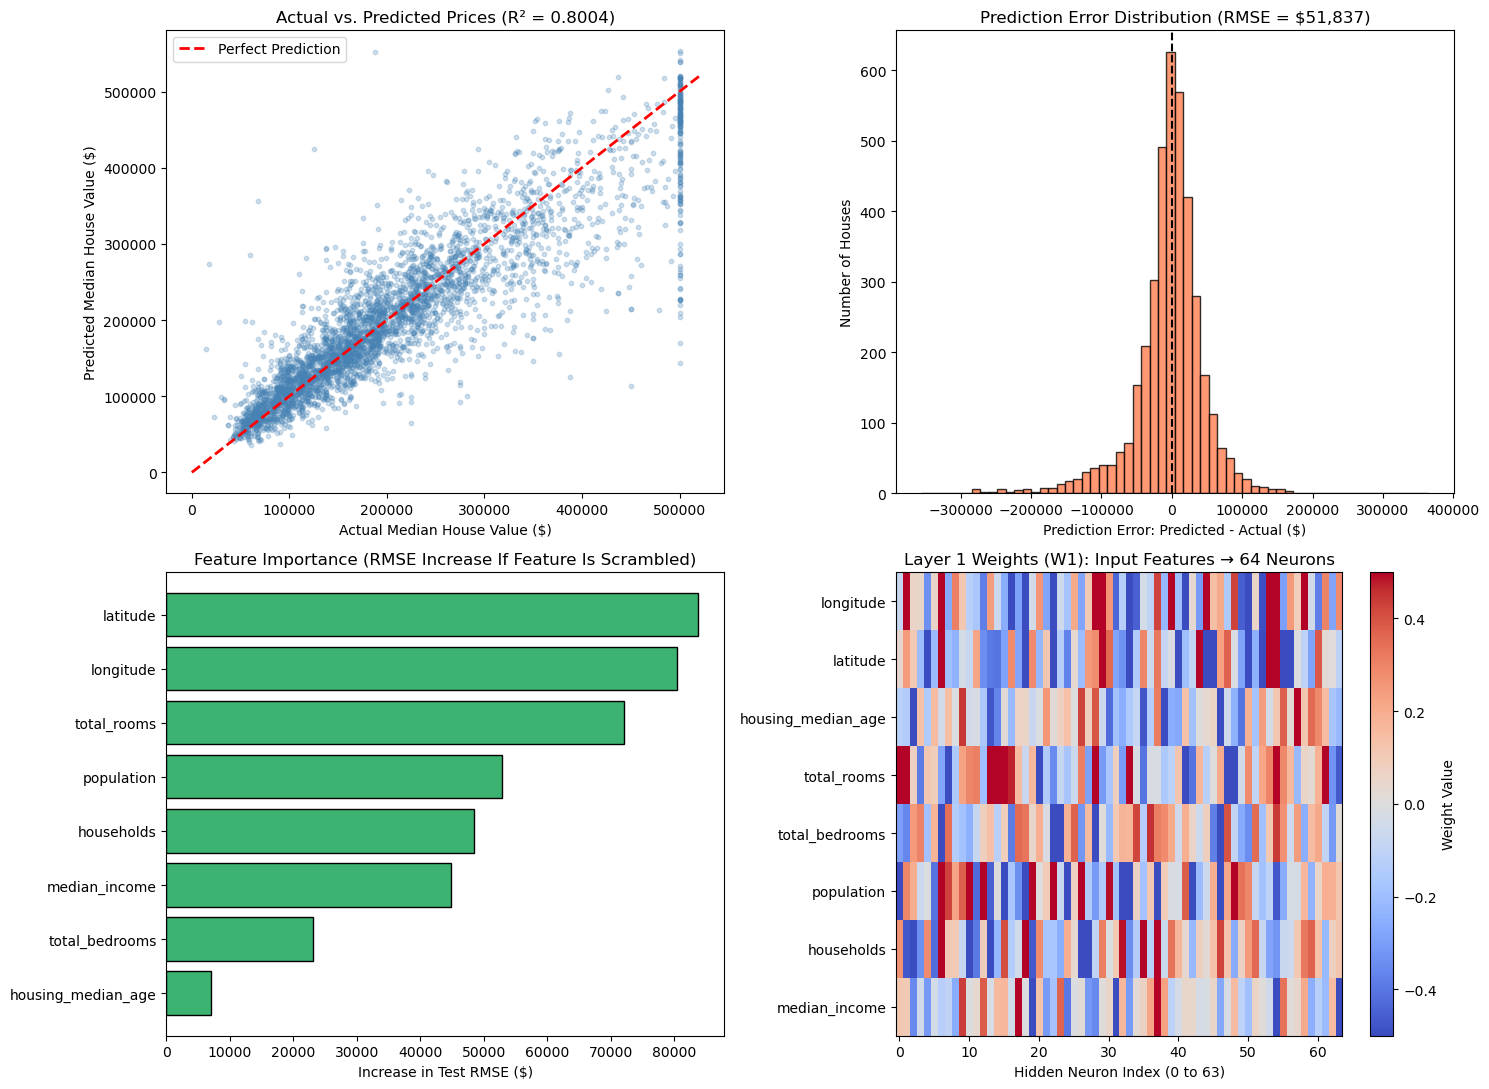

In [7]:
# Visualizing Model
import matplotlib.pyplot as plt

# Helper function to run forward pass cleanly
def predict_dollars(X_input):
    with torch.no_grad():
        A1 = torch.clamp(X_input @ W1 + b1, min=0.0)
        A2 = torch.clamp(A1 @ W2 + b2, min=0.0)
        return (A2 @ W3 + b3) * 100000.0

feature_names = list(X_test.columns)
y_pred = predict_dollars(X_t_scaled)
baseline_rmse = torch.sqrt(torch.mean((y_pred - y_t) ** 2)).item()

# 1. Calculate Permutation Feature Importance (how much RMSE increases when a feature is shuffled)
importances = []
torch.manual_seed(42)
for col_idx in range(X_t_scaled.shape[1]):
    X_permuted = X_t_scaled.clone()
    shuffled_idx = torch.randperm(X_permuted.shape[0])
    X_permuted[:, col_idx] = X_permuted[shuffled_idx, col_idx]
    
    perm_pred = predict_dollars(X_permuted)
    perm_rmse = torch.sqrt(torch.mean((perm_pred - y_t) ** 2)).item()
    importances.append(perm_rmse - baseline_rmse)

# Sort features from most important to least important
sorted_idx = np.argsort(importances)
sorted_names = [feature_names[i] for i in sorted_idx]
sorted_imp = [importances[i] for i in sorted_idx]

# --- Create 2x2 Diagnostic Dashboard ---
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Plot 1: Actual vs. Predicted House Prices
y_actual_np = y_t.numpy().flatten()
y_pred_np = y_pred.numpy().flatten()
axes[0, 0].scatter(y_actual_np, y_pred_np, alpha=0.25, s=10, color='steelblue')
axes[0, 0].plot([0, 520000], [0, 520000], 'r--', lw=2, label='Perfect Prediction')
axes[0, 0].set_title(f'Actual vs. Predicted Prices (R² = 0.8004)')
axes[0, 0].set_xlabel('Actual Median House Value ($)')
axes[0, 0].set_ylabel('Predicted Median House Value ($)')
axes[0, 0].legend()

# Plot 2: Residual Errors (Predicted - Actual)
residuals = y_pred_np - y_actual_np
axes[0, 1].hist(residuals, bins=60, color='coral', edgecolor='black', alpha=0.8)
axes[0, 1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[0, 1].set_title(f'Prediction Error Distribution (RMSE = ${baseline_rmse:,.0f})')
axes[0, 1].set_xlabel('Prediction Error: Predicted - Actual ($)')
axes[0, 1].set_ylabel('Number of Houses')

# Plot 3: True Feature Importance (RMSE Increase When Shuffled)
axes[1, 0].barh(sorted_names, sorted_imp, color='mediumseagreen', edgecolor='black')
axes[1, 0].set_title('Feature Importance (RMSE Increase If Feature Is Scrambled)')
axes[1, 0].set_xlabel('Increase in Test RMSE ($)')

# Plot 4: Layer 1 Weight Matrix Heatmap (W1: Features -> 64 Hidden Neurons)
im = axes[1, 1].imshow(W1.detach().numpy(), aspect='auto', cmap='coolwarm', vmin=-0.5, vmax=0.5)
axes[1, 1].set_yticks(range(len(feature_names)))
axes[1, 1].set_yticklabels(feature_names)
axes[1, 1].set_title('Layer 1 Weights (W1): Input Features → 64 Neurons')
axes[1, 1].set_xlabel('Hidden Neuron Index (0 to 63)')
fig.colorbar(im, ax=axes[1, 1], label='Weight Value')

plt.tight_layout()
plt.show()